### Question 1 – Dataset Choice

Choose ONE classification dataset of your choice from any public repository (Kaggle or UCI).

- It may be a binary classification problem or a multi-class classification problem.
- **Minimum Feature Size:** 12
- **Minimum Instance Size:** 500

In [4]:
import pandas as pd

spambase = pd.read_csv("../data/spambase.data", header=None)

names_file = open("../data/spambase.names", "r")
names = names_file.read()
names_file.close()

documentation_file = open("../data/spambase.DOCUMENTATION", "r")
documentation = documentation_file.read()
documentation_file.close()


print("Number of instances:", spambase.shape[0])
print("Number of features:", spambase.shape[1] - 1)
print("\nActual dataset:")
print(spambase.shape)
print(spambase.head())

print("\nFeature definitions:")
print(names)

print("\nDataset documentation:")
print(documentation)

Number of instances: 4601
Number of features: 57

Actual dataset:
(4601, 58)
     0     1     2    3     4     5     6     7     8     9   ...    48  \
0  0.00  0.64  0.64  0.0  0.32  0.00  0.00  0.00  0.00  0.00  ...  0.00   
1  0.21  0.28  0.50  0.0  0.14  0.28  0.21  0.07  0.00  0.94  ...  0.00   
2  0.06  0.00  0.71  0.0  1.23  0.19  0.19  0.12  0.64  0.25  ...  0.01   
3  0.00  0.00  0.00  0.0  0.63  0.00  0.31  0.63  0.31  0.63  ...  0.00   
4  0.00  0.00  0.00  0.0  0.63  0.00  0.31  0.63  0.31  0.63  ...  0.00   

      49   50     51     52     53     54   55    56  57  
0  0.000  0.0  0.778  0.000  0.000  3.756   61   278   1  
1  0.132  0.0  0.372  0.180  0.048  5.114  101  1028   1  
2  0.143  0.0  0.276  0.184  0.010  9.821  485  2259   1  
3  0.137  0.0  0.137  0.000  0.000  3.537   40   191   1  
4  0.135  0.0  0.135  0.000  0.000  3.537   40   191   1  

[5 rows x 58 columns]

Feature definitions:
| SPAM E-MAIL DATABASE ATTRIBUTES (in .names format)
|
| 48 continuous re

Implement the following five classification models using the dataset selected in Question 1.

**All five ML models must be implemented on the same dataset.**

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor (KNN) Classifier
4. Naive Bayes Classifier (Gaussian or Multinomial)
5. Support Vector Machine (SVM)

In [5]:
# Data preprocessing

# check for missing values
print("missing values : ", spambase.isnull().sum().sum())

# check for duplicates and ambiguous cases
duplicate_rows = []
ambiguous_rows = []
unique_rows = []


features = spambase.iloc[:, :-1]
target = spambase.iloc[:, -1]


feature_groups = {}

for i in range(len(spambase)):

    feature_values = tuple(features.iloc[i])

    if feature_values in feature_groups:
        feature_groups[feature_values].append(i)

    else:
        feature_groups[feature_values] = [i]

for matching_rows in feature_groups.values():

    if len(matching_rows) == 1:
        unique_rows.append(matching_rows[0])

    else:
        labels = []

        for row in matching_rows:
            labels.append(target.iloc[row])

        if len(set(labels)) == 1:
            duplicate_rows.append(matching_rows)

        else:
            ambiguous_rows.append(matching_rows)

print("Exact duplicate records:", spambase.duplicated().sum())            
print("Unique predictor combinations:", len(unique_rows))
print("Ambiguous groups:", len(ambiguous_rows))

# clean duplicate and ambiguous groups 

spambase_cleaned = spambase.copy()
rows_to_keep = []

for group in feature_groups.values():

    if len(group) == 1:
        rows_to_keep.append(group[0])

    else:
        labels = target.iloc[group].unique()

        if len(labels) == 1:
            rows_to_keep.append(group[0])

spambase_cleaned = spambase.iloc[rows_to_keep].copy()

print("Original dataset shape:", spambase.shape)
print("Cleaned dataset shape:", spambase_cleaned.shape)
print("Remaining exact duplicates:", spambase_cleaned.duplicated().sum())

X = spambase_cleaned.iloc[:, :-1]
y = spambase_cleaned.iloc[:, -1]

missing values :  0
Exact duplicate records: 391
Unique predictor combinations: 4024
Ambiguous groups: 3
Original dataset shape: (4601, 58)
Cleaned dataset shape: (4204, 58)
Remaining exact duplicates: 0


In [12]:
#test train split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

test_data = X_test.copy()
test_data["target"] = y_test

test_data.to_csv("../test_data.csv", index=False)

#Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the fitted scaler
joblib.dump(scaler, "../model/scaler.joblib")

['../model/scaler.joblib']

In [14]:
# import classifiers

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


logistic_model = LogisticRegression(max_iter=1000, random_state=42)

decision_tree_model = DecisionTreeClassifier(random_state=42)

knn_model = KNeighborsClassifier()

naive_bayes_model = GaussianNB()

svm_model = SVC(probability=True, random_state=42)

#train models using train data

logistic_model.fit(X_train_scaled, y_train)

decision_tree_model.fit(X_train, y_train)

knn_model.fit(X_train_scaled, y_train)

naive_bayes_model.fit(X_train, y_train)

svm_model.fit(X_train_scaled, y_train)

#store the models
joblib.dump(logistic_model, "../model/logistic_regression.joblib")

joblib.dump(decision_tree_model, "../model/decision_tree.joblib")

joblib.dump(knn_model, "../model/knn.joblib")

joblib.dump(naive_bayes_model, "../model/naive_bayes.joblib")

joblib.dump(svm_model, "../model/svm.joblib")

#predict using test data

logistic_predictions = logistic_model.predict(X_test_scaled)

decision_tree_predictions = decision_tree_model.predict(X_test)

knn_predictions = knn_model.predict(X_test_scaled)

naive_bayes_predictions = naive_bayes_model.predict(X_test)

svm_predictions = svm_model.predict(X_test_scaled)

# ROC- AUC
logistic_scores = logistic_model.predict_proba(X_test_scaled)[:, 1]

decision_tree_scores = decision_tree_model.predict_proba(X_test)[:, 1]

knn_scores = knn_model.predict_proba(X_test_scaled)[:, 1]

naive_bayes_scores = naive_bayes_model.predict_proba(X_test)[:, 1]

svm_scores = svm_model.predict_proba(X_test_scaled)[:, 1]

### Question 3 – Evaluation Metrics

Calculate the following six evaluation metrics for each of the five classification models:

1. Accuracy
2. AUC Score (ROC-AUC)
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC Score)

In [16]:
#metrics evaluation

#import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import matthews_corrcoef

results = {
    "Logistic Regression": [
        accuracy_score(y_test, logistic_predictions),
        roc_auc_score(y_test, logistic_scores),
        precision_score(y_test, logistic_predictions),
        recall_score(y_test, logistic_predictions),
        f1_score(y_test, logistic_predictions),
        matthews_corrcoef(y_test, logistic_predictions)
    ],

    "Decision Tree": [
        accuracy_score(y_test, decision_tree_predictions),
        roc_auc_score(y_test, decision_tree_scores),
        precision_score(y_test, decision_tree_predictions),
        recall_score(y_test, decision_tree_predictions),
        f1_score(y_test, decision_tree_predictions),
        matthews_corrcoef(y_test, decision_tree_predictions)
    ],

    "KNN": [
        accuracy_score(y_test, knn_predictions),
        roc_auc_score(y_test, knn_scores),
        precision_score(y_test, knn_predictions),
        recall_score(y_test, knn_predictions),
        f1_score(y_test, knn_predictions),
        matthews_corrcoef(y_test, knn_predictions)
    ],

    "Gaussian Naive Bayes": [
        accuracy_score(y_test, naive_bayes_predictions),
        roc_auc_score(y_test, naive_bayes_scores),
        precision_score(y_test, naive_bayes_predictions),
        recall_score(y_test, naive_bayes_predictions),
        f1_score(y_test, naive_bayes_predictions),
        matthews_corrcoef(y_test, naive_bayes_predictions)
    ],

    "SVM": [
        accuracy_score(y_test, svm_predictions),
        roc_auc_score(y_test, svm_scores),
        precision_score(y_test, svm_predictions),
        recall_score(y_test, svm_predictions),
        f1_score(y_test, svm_predictions),
        matthews_corrcoef(y_test, svm_predictions)
    ]
}


#display metrics comparision

results_table = pd.DataFrame(
    results,
    index=[
        "Accuracy",
        "ROC-AUC",
        "Precision",
        "Recall",
        "F1 Score",
        "MCC"
    ]
).T

print(results_table.round(4))

                      Accuracy  ROC-AUC  Precision  Recall  F1 Score     MCC
Logistic Regression     0.9239   0.9721     0.9045  0.9045    0.9045  0.8412
Decision Tree           0.9227   0.9186     0.9066  0.8985    0.9025  0.8385
KNN                     0.9168   0.9654     0.9027  0.8866    0.8946  0.8259
Gaussian Naive Bayes    0.8252   0.9498     0.7035  0.9701    0.8156  0.6881
SVM                     0.9310   0.9766     0.9184  0.9075    0.9129  0.8559


In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
logistic_cm = confusion_matrix(y_test, logistic_predictions)
print("Logistic Regression")
print("TN:", logistic_cm[0, 0])
print("FP:", logistic_cm[0, 1])
print("FN:", logistic_cm[1, 0])
print("TP:", logistic_cm[1, 1])

decision_tree_cm = confusion_matrix(y_test, decision_tree_predictions)
print("\nDecision Tree")
print("TN:", decision_tree_cm[0, 0])
print("FP:", decision_tree_cm[0, 1])
print("FN:", decision_tree_cm[1, 0])
print("TP:", decision_tree_cm[1, 1])

knn_cm = confusion_matrix(y_test, knn_predictions)
print("\nKNN")
print("TN:", knn_cm[0, 0])
print("FP:", knn_cm[0, 1])
print("FN:", knn_cm[1, 0])
print("TP:", knn_cm[1, 1])

naive_bayes_cm = confusion_matrix(y_test, naive_bayes_predictions)
print("\nGaussian Naive Bayes")
print("TN:", naive_bayes_cm[0, 0])
print("FP:", naive_bayes_cm[0, 1])
print("FN:", naive_bayes_cm[1, 0])
print("TP:", naive_bayes_cm[1, 1])

svm_cm = confusion_matrix(y_test, svm_predictions)
print("\nSVM")
print("TN:", svm_cm[0, 0])
print("FP:", svm_cm[0, 1])
print("FN:", svm_cm[1, 0])
print("TP:", svm_cm[1, 1])

Logistic Regression
TN: 474
FP: 32
FN: 32
TP: 303

Decision Tree
TN: 475
FP: 31
FN: 34
TP: 301

KNN
TN: 474
FP: 32
FN: 38
TP: 297

Gaussian Naive Bayes
TN: 369
FP: 137
FN: 10
TP: 325

SVM
TN: 479
FP: 27
FN: 31
TP: 304


In [18]:

# Logistic Regression
print("Logistic Regression")

print("Class 0 - Non-spam")
print("Precision:", precision_score(y_test, logistic_predictions, pos_label=0))
print("Recall:", recall_score(y_test, logistic_predictions, pos_label=0))
print("F1-score:", f1_score(y_test, logistic_predictions, pos_label=0))

print("Class 1 - Spam")
print("Precision:", precision_score(y_test, logistic_predictions, pos_label=1))
print("Recall:", recall_score(y_test, logistic_predictions, pos_label=1))
print("F1-score:", f1_score(y_test, logistic_predictions, pos_label=1))


# Decision Tree
print("\nDecision Tree")

print("Class 0 - Non-spam")
print("Precision:", precision_score(y_test, decision_tree_predictions, pos_label=0))
print("Recall:", recall_score(y_test, decision_tree_predictions, pos_label=0))
print("F1-score:", f1_score(y_test, decision_tree_predictions, pos_label=0))

print("Class 1 - Spam")
print("Precision:", precision_score(y_test, decision_tree_predictions, pos_label=1))
print("Recall:", recall_score(y_test, decision_tree_predictions, pos_label=1))
print("F1-score:", f1_score(y_test, decision_tree_predictions, pos_label=1))


# KNN
print("\nKNN")

print("Class 0 - Non-spam")
print("Precision:", precision_score(y_test, knn_predictions, pos_label=0))
print("Recall:", recall_score(y_test, knn_predictions, pos_label=0))
print("F1-score:", f1_score(y_test, knn_predictions, pos_label=0))

print("Class 1 - Spam")
print("Precision:", precision_score(y_test, knn_predictions, pos_label=1))
print("Recall:", recall_score(y_test, knn_predictions, pos_label=1))
print("F1-score:", f1_score(y_test, knn_predictions, pos_label=1))


# Gaussian Naive Bayes
print("\nGaussian Naive Bayes")

print("Class 0 - Non-spam")
print("Precision:", precision_score(y_test, naive_bayes_predictions, pos_label=0))
print("Recall:", recall_score(y_test, naive_bayes_predictions, pos_label=0))
print("F1-score:", f1_score(y_test, naive_bayes_predictions, pos_label=0))

print("Class 1 - Spam")
print("Precision:", precision_score(y_test, naive_bayes_predictions, pos_label=1))
print("Recall:", recall_score(y_test, naive_bayes_predictions, pos_label=1))
print("F1-score:", f1_score(y_test, naive_bayes_predictions, pos_label=1))


# SVM
print("\nSVM")

print("Class 0 - Non-spam")
print("Precision:", precision_score(y_test, svm_predictions, pos_label=0))
print("Recall:", recall_score(y_test, svm_predictions, pos_label=0))
print("F1-score:", f1_score(y_test, svm_predictions, pos_label=0))

print("Class 1 - Spam")
print("Precision:", precision_score(y_test, svm_predictions, pos_label=1))
print("Recall:", recall_score(y_test, svm_predictions, pos_label=1))
print("F1-score:", f1_score(y_test, svm_predictions, pos_label=1))


Logistic Regression
Class 0 - Non-spam
Precision: 0.9367588932806324
Recall: 0.9367588932806324
F1-score: 0.9367588932806324
Class 1 - Spam
Precision: 0.9044776119402985
Recall: 0.9044776119402985
F1-score: 0.9044776119402985

Decision Tree
Class 0 - Non-spam
Precision: 0.9332023575638507
Recall: 0.9387351778656127
F1-score: 0.9359605911330049
Class 1 - Spam
Precision: 0.9066265060240963
Recall: 0.8985074626865671
F1-score: 0.9025487256371814

KNN
Class 0 - Non-spam
Precision: 0.92578125
Recall: 0.9367588932806324
F1-score: 0.931237721021611
Class 1 - Spam
Precision: 0.9027355623100304
Recall: 0.8865671641791045
F1-score: 0.8945783132530121

Gaussian Naive Bayes
Class 0 - Non-spam
Precision: 0.9736147757255936
Recall: 0.7292490118577075
F1-score: 0.8338983050847457
Class 1 - Spam
Precision: 0.7034632034632035
Recall: 0.9701492537313433
F1-score: 0.8155583437892095

SVM
Class 0 - Non-spam
Precision: 0.9392156862745098
Recall: 0.9466403162055336
F1-score: 0.9429133858267716
Class 1 - Spa

### ROC Curve Comparison

Plot the Receiver Operating Characteristic (ROC) curves for all five classification models on the same graph to compare their classification performance.

Compare the curves using the Area Under the Curve (AUC) scores.

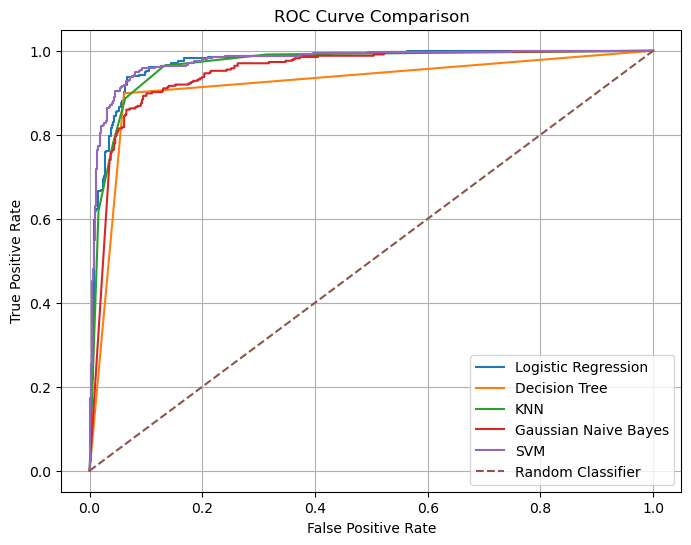

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, logistic_scores)
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, decision_tree_scores)
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y_test, knn_scores)
fpr_nb, tpr_nb, thresholds_nb = roc_curve(y_test, naive_bayes_scores)
fpr_svm, tpr_svm, thresholds_svm = roc_curve(y_test, svm_scores)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label="Logistic Regression")
plt.plot(fpr_dt, tpr_dt, label="Decision Tree")
plt.plot(fpr_knn, tpr_knn, label="KNN")
plt.plot(fpr_nb, tpr_nb, label="Gaussian Naive Bayes")
plt.plot(fpr_svm, tpr_svm, label="SVM")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()